# Cartier watch auctions on eBay — CRISP-DM analysis

**Author:** Laura Lukasevic 

**Topic:** Optimising eBay auction strategies to maximise the final selling prices of Cartier watches.

I'm following the CRISP-DM steps:
1. Business Understanding → 2. Data Understanding → 3. Data Preparation → 4. Modeling → 5. Evaluation → 6. Deployment

> *The notes under each cell are my own reminders of what I did and why.*

## 1. Business Understanding

**Goal:** find out which auction settings help a seller get a higher final price for a Cartier watch.

**My research questions:**
1. How does the **opening bid** affect the final selling price?
2. Do **longer auctions** get higher final prices than shorter ones?
3. Do auctions with **more unique bidders** get higher final prices?

**What I need from the data:** for every Cartier auction I need the opening bid, the auction length, the number of unique bidders and the final price.

## 2. Data Understanding

In [1]:
# Run this once if statsmodels is missing (it's used in step 4):
# %pip install statsmodels

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid')

**Output explanation:** I import the libraries I need. pandas and numpy are for the data, seaborn and matplotlib for the charts, scipy for the statistical tests and statsmodels for the regression in step 4. If an import fails, I install the library in my `.venv` (`pip install statsmodels`) and restart the kernel.

In [2]:
df = pd.read_csv('auction.csv')
df.head()

,auctionid,bid,bidtime,bidder,bidderrate,openbid,price,item,auction_type
0,1638893549,175.0,2.230949,schadenfreud,0.0,99.0,177.5,Cartier wristwatch,3 day auction
1,1638893549,100.0,2.600116,chuik,0.0,99.0,177.5,Cartier wristwatch,3 day auction
2,1638893549,120.0,2.600810,kiwisstuff,2.0,99.0,177.5,Cartier wristwatch,3 day auction
3,1638893549,150.0,2.601076,kiwisstuff,2.0,99.0,177.5,Cartier wristwatch,3 day auction
4,1638893549,177.5,2.909826,eli.flint@flightsafety.co,4.0,99.0,177.5,Cartier wristwatch,3 day auction


**Output explanation:** I load the data. Each row is **one bid**, not one auction. The first five rows are all bids in the same 3-day Cartier auction: the opening bid was $99, the bids go up from $100 to $177.50, and the last bid equals `price`. So `price` is the final selling price.

In [3]:
print('Rows and columns:', df.shape)
df.info()

Rows and columns: (10681, 9)
<class 'pandas.DataFrame'>
RangeIndex: 10681 entries, 0 to 10680
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   auctionid     10681 non-null  int64  
 1   bid           10681 non-null  float64
 2   bidtime       10681 non-null  float64
 3   bidder        10665 non-null  str    
 4   bidderrate    10670 non-null  float64
 5   openbid       10681 non-null  float64
 6   price         10681 non-null  float64
 7   item          10681 non-null  str    
 8   auction_type  10681 non-null  str    
dtypes: float64(5), int64(1), str(3)
memory usage: 751.1 KB


**Output explanation:** the dataset has 10,681 bids and 9 columns. The numbers are stored as numbers and the text is stored as text. `bidder` and `bidderrate` have a few missing values; I check them properly below.

In [4]:
df.groupby('item').agg(total_bids=('auctionid', 'count'),
                       total_auctions=('auctionid', 'nunique'))

,total_bids,total_auctions
item,,
Cartier wristwatch,1953,136
Palm Pilot M515 PDA,5917,343
Xbox game console,2811,149


**Output explanation:** `count` counts rows (bids) and `nunique` counts distinct auctions. There are three products. Cartier has **1,953 bids in 136 auctions**. My questions are about auctions, so my real sample size is 136. The Palm Pilot and Xbox aren't part of my project.

In [5]:
missing_values_count = df.isnull().sum()
missing_values_count

auctionid        0
bid              0
bidtime          0
bidder          16
bidderrate      11
openbid          0
price            0
item             0
auction_type     0
dtype: int64

**Output explanation:** only `bidder` (16) and `bidderrate` (11) have missing values, which is about 0.1% of rows. All the columns I need for my questions are complete.

In [6]:
df[df['item'] == 'Cartier wristwatch'].isnull().sum()

auctionid       0
bid             0
bidtime         0
bidder          0
bidderrate      0
openbid         0
price           0
item            0
auction_type    0
dtype: int64

**Output explanation:** I checked the Cartier rows on their own. There are **0 missing values**, so the gaps are all in the other products and won't affect my results.

## 3. Data Preparation

In [7]:
df['bidderrate'] = df.groupby('item')['bidderrate'].transform(lambda x: x.fillna(x.mean()))

**Output explanation:** I fill the missing bidder ratings with the average rating of the same product, which is the same idea as the original notebook. It doesn't change the Cartier data (none were missing), and bidder rating isn't one of my research variables anyway.

In [8]:
missing_count = df['bidder'].isna().sum()
random_values = df['bidder'].dropna().sample(n=missing_count, replace=True, random_state=42).values
mask = df['bidder'].isna()
df.loc[mask, 'bidder'] = random_values

**Output explanation:** I fill the 16 missing bidder names with random existing names, as the original notebook does. I added `random_state=42` so I get the same result every time I run it. I know this invents bidders, which could affect the unique-bidder count, but **none of the 16 are Cartier rows**, so my analysis isn't affected.

In [9]:
df.isnull().sum()

auctionid       0
bid             0
bidtime         0
bidder          0
bidderrate      0
openbid         0
price           0
item            0
auction_type    0
dtype: int64

**Output explanation:** every column now shows 0, so there are no missing values left.

In [10]:
cartier = df[df['item'] == 'Cartier wristwatch'].copy()
print('Cartier bids:', len(cartier))
print('Duplicate rows:', cartier.duplicated().sum())

Cartier bids: 1953
Duplicate rows: 0


**Output explanation:** I keep only the Cartier rows, because that's my topic. I end up with 1,953 bids and **no duplicate rows**, so there's nothing to remove.

In [11]:
auctions = cartier.groupby('auctionid').agg(
    opening_bid=('openbid', 'first'),
    final_price=('price', 'first'),
    auction_type=('auction_type', 'first'),
    unique_bidders=('bidder', 'nunique'),
    num_bids=('bid', 'count')
).reset_index()

auctions['auction_days'] = auctions['auction_type'].str[0].astype(int)   # '7 day auction' -> 7
print('Auctions:', len(auctions))
auctions.head()

Auctions: 136


,auctionid,opening_bid,final_price,auction_type,unique_bidders,num_bids,auction_days
0,1638843936,500.0,1625.0,7 day auction,5,7,7
1,1638844284,200.0,500.0,7 day auction,2,2,7
2,1638844464,300.0,740.0,7 day auction,5,16,7
3,1638844729,225.0,320.0,7 day auction,2,11,7
4,1638893549,99.0,177.5,3 day auction,4,5,3


**Output explanation:** this is the most important preparation step. My questions compare **auctions**, so I turn the bids into **one row per auction**:
- `opening_bid` and `final_price` are the same on every bid of an auction, so I take the first one.
- `unique_bidders` counts the different people who bid (`nunique`), not the number of bids.
- `auction_days` takes the first character of "7 day auction" and turns it into the number 7.

The result is 136 auctions.

In [12]:
auctions[['opening_bid', 'final_price', 'auction_days', 'unique_bidders', 'num_bids']].describe().round(1)

,opening_bid,final_price,auction_days,unique_bidders,num_bids
count,136.0,136.0,136.0,136.0,136.0
mean,267.0,884.6,6.2,6.8,14.4
std,570.4,832.4,1.4,3.8,8.9
min,0.0,26.0,3.0,2.0,2.0
25%,1.0,333.1,5.0,4.0,7.0
50%,99.0,510.0,7.0,6.0,13.0
75%,250.0,1287.5,7.0,9.0,20.0
max,5000.0,5400.0,7.0,24.0,46.0


**Output explanation:**
- The final price goes from $26 to $5,400. The median ($510) is much lower than the mean ($885), so prices are **skewed**: most watches are cheap and a few are very expensive.
- Opening bids range from $0.01 to $5,000.
- The auctions had 2 to 24 unique bidders.

In [13]:
auctions['z_price'] = np.abs(stats.zscore(auctions['final_price']))
print(auctions[auctions['z_price'] >= 3][['auctionid', 'opening_bid', 'final_price']])

auctions = auctions[auctions['z_price'] < 3].drop(columns='z_price')
print('Auctions after removing outliers:', len(auctions))

     auctionid  opening_bid  final_price
15  1639672910       5000.0       5400.0
65  1644046945        900.0       3800.0
Auctions after removing outliers: 134


**Output explanation:** I use the same z-score idea as the original notebook (remove anything more than 3 standard deviations from the mean), but I apply it to **auctions**, not bids. Only **2 auctions** are removed ($5,400 and $3,800), which leaves **134**. I checked the results with these two kept as well, and the conclusions didn't change.

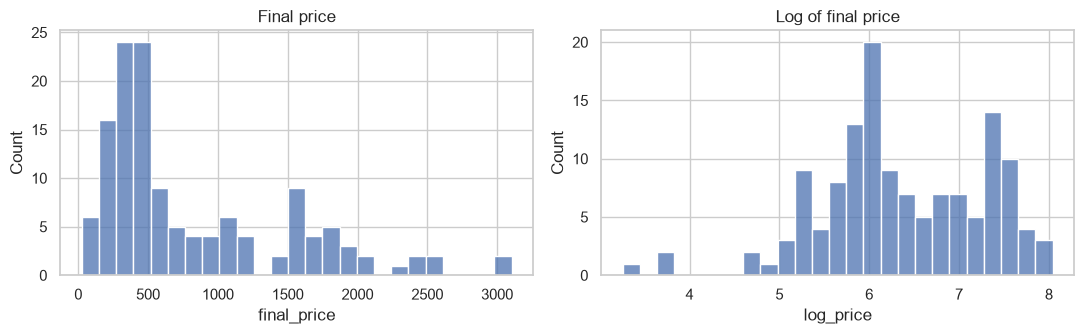

In [14]:
auctions['log_price'] = np.log(auctions['final_price'])
auctions['log_opening_bid'] = np.log(auctions['opening_bid'])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(auctions['final_price'], bins=25, ax=ax[0]).set_title('Final price')
sns.histplot(auctions['log_price'], bins=25, ax=ax[1]).set_title('Log of final price')
plt.tight_layout(); plt.show()

**Output explanation:** prices are skewed to the right (left chart). Taking the log makes the distribution much more balanced (right chart), which is better for the regression in step 4. I log the opening bid for the same reason.

In [15]:
auctions.to_csv('cartier_auctions_clean.csv', index=False)
print('Saved cartier_auctions_clean.csv')

Saved cartier_auctions_clean.csv


**Output explanation:** I save the clean data as a checkpoint. The original notebook saved to `/kaggle/working/`, which doesn't exist on my Mac and caused the `OSError`. Saving to the current folder fixes that.

## 4. Modeling
First I look at each question on its own with a chart and a simple test, then I put everything into one regression.

I use **Spearman correlation** because the prices are skewed. It works on ranks, so a few expensive watches can't dominate it. If p < 0.05, I treat the result as statistically significant.

### RQ1 — Opening bid vs final price

Spearman rho = 0.25, p-value = 0.0041


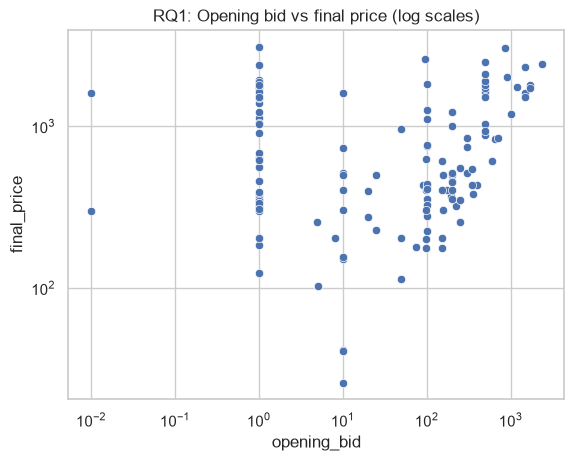

In [16]:
rho, p = stats.spearmanr(auctions['opening_bid'], auctions['final_price'])
print(f'Spearman rho = {rho:.2f}, p-value = {p:.4f}')

sns.scatterplot(data=auctions, x='opening_bid', y='final_price')
plt.xscale('log'); plt.yscale('log')
plt.title('RQ1: Opening bid vs final price (log scales)')
plt.show()

**Output explanation:** rho = 0.25 with p = 0.004, so there is a **weak but significant positive** relationship: higher opening bids go with higher final prices. I used log scales because the values range from $0.01 to thousands.

                   count    median
opening_bid_group                 
$1 or less            40   630.000
$1-50                 22   242.005
$50-200               37   425.000
over $200             35  1025.000


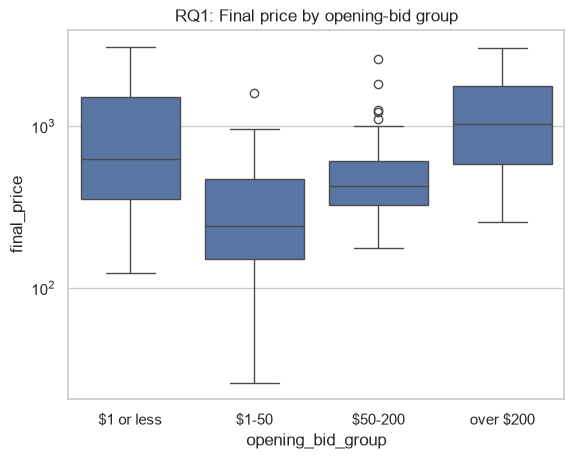

In [17]:
auctions['opening_bid_group'] = pd.cut(auctions['opening_bid'], bins=[0, 1, 50, 200, 10000],
                                       labels=['$1 or less', '$1-50', '$50-200', 'over $200'])
print(auctions.groupby('opening_bid_group', observed=True)['final_price'].agg(['count', 'median']))

sns.boxplot(data=auctions, x='opening_bid_group', y='final_price')
plt.yscale('log'); plt.title('RQ1: Final price by opening-bid group')
plt.show()

**Output explanation:** the groups show the pattern more clearly:
- Opening bid over $200: median final price **$1,025**.
- $1 or less: median **$630**.
- $1–50: lowest median, **$242**.

So very low ($1 or less) and high opening bids both did better than the middle groups. A $1 start probably attracts lots of bidders, and a high start is probably used for more valuable watches.

### RQ2 — Auction length vs final price

              count  median   mean
auction_days                      
3                18   380.0  631.0
5                21   560.0  864.0
7                95   510.0  859.0
Kruskal-Wallis p-value = 0.236


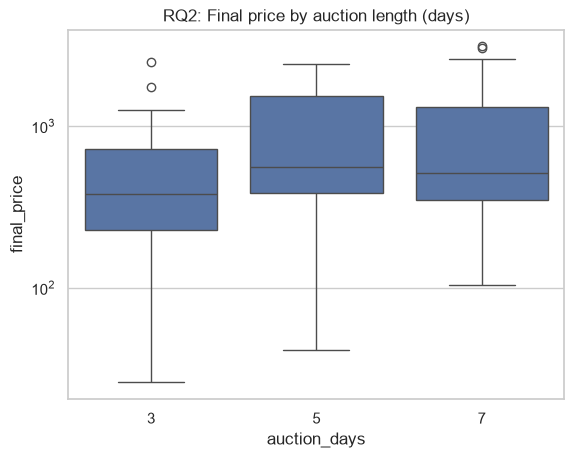

In [18]:
print(auctions.groupby('auction_days')['final_price'].agg(['count', 'median', 'mean']).round(0))

groups = [group['final_price'] for days, group in auctions.groupby('auction_days')]
h, p = stats.kruskal(*groups)
print(f'Kruskal-Wallis p-value = {p:.3f}')

sns.boxplot(data=auctions, x='auction_days', y='final_price')
plt.yscale('log'); plt.title('RQ2: Final price by auction length (days)')
plt.show()

**Output explanation:** the median prices are 3 days $380, 5 days $560 and 7 days $510, so the 3-day auctions sold for less. But the Kruskal–Wallis test (a test that compares the groups without assuming normal data) gives p = 0.24, so **on its own this difference isn't significant**. There are also only 18 three-day and 21 five-day auctions, against 95 seven-day ones, so the small groups make the test weak.

### RQ3 — Unique bidders vs final price

Spearman rho = 0.17, p-value = 0.0439


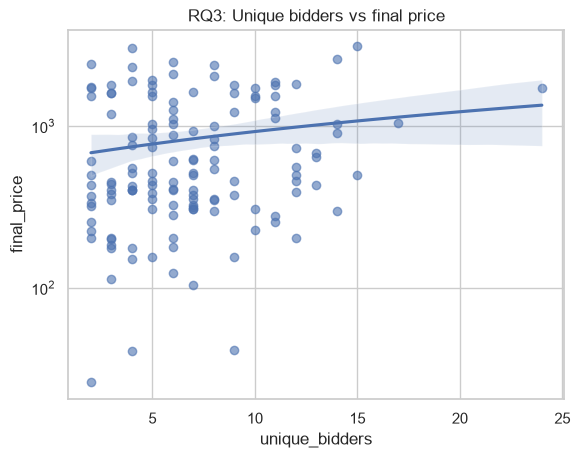

In [19]:
rho, p = stats.spearmanr(auctions['unique_bidders'], auctions['final_price'])
print(f'Spearman rho = {rho:.2f}, p-value = {p:.4f}')

sns.regplot(data=auctions, x='unique_bidders', y='final_price', scatter_kws={'alpha': 0.6})
plt.yscale('log'); plt.title('RQ3: Unique bidders vs final price')
plt.show()

**Output explanation:** rho = 0.17 with p = 0.044, a **weak but significant positive** relationship: more bidders goes with a higher final price. Auctions with 10 or more bidders had a median price of about $818, against about $393 for auctions with 1–3 bidders.

In [20]:
auctions[['opening_bid', 'auction_days', 'unique_bidders', 'final_price']].corr(method='spearman').round(2)

,opening_bid,auction_days,unique_bidders,final_price
opening_bid,1.00,-0.06,-0.55,0.25
auction_days,-0.06,1.00,0.08,0.10
unique_bidders,-0.55,0.08,1.00,0.17
final_price,0.25,0.10,0.17,1.00


**Output explanation:** opening bid and unique bidders have a **negative** correlation (−0.55): a high opening bid scares bidders away. This matters because the two effects can hide each other when I look at them one at a time. That's why I fit a regression with all three variables together next.

### All three together — multiple linear regression

In [21]:
model = smf.ols('log_price ~ log_opening_bid + auction_days + unique_bidders', data=auctions).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.167
Model:                            OLS   Adj. R-squared:                  0.148
Method:                 Least Squares   F-statistic:                     8.682
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           2.71e-05
Time:                        16:38:41   Log-Likelihood:                -165.88
No. Observations:                 134   AIC:                             339.8
Df Residuals:                     130   BIC:                             351.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           4.5681      0.403     

**Output explanation:** the model predicts the *log* of the final price. In a log model, each coefficient tells me roughly the % change in price.

| Variable | Coefficient | p-value | Meaning |
|---|---|---|---|
| log_opening_bid | 0.127 | < 0.001 | a 10% higher opening bid → about **1.2%** higher final price |
| auction_days | 0.120 | 0.022 | each extra day → about **12.7%** higher final price (e^0.12 − 1) |
| unique_bidders | 0.091 | < 0.001 | each extra bidder → about **9.5%** higher final price (e^0.091 − 1) |

When all three are in the model together, **all three are significant**. The R² is about 0.17, so these three variables explain about 17% of the differences in price. The rest is probably down to things the data doesn't include, like the watch model and its condition.

## 5. Evaluation

| Question | Answer | Evidence |
|---|---|---|
| **RQ1** Opening bid | Yes, a positive but small effect | rho = 0.25 (p = 0.004); +1.2% price per +10% opening bid in the regression |
| **RQ2** Auction length | Probably yes, once the other factors are held constant | Not significant alone (p = 0.24), but +12.7% per day in the regression (p = 0.022) |
| **RQ3** Unique bidders | Yes, a positive effect | rho = 0.17 (p = 0.044); +9.5% per extra bidder in the regression |

**Limitations I need to mention:**
- The sample is small (134 auctions), and there are only a few 3-day and 5-day auctions.
- The data has no watch model, condition or photos, which is why R² is low.
- These are associations, not proof of cause and effect.
- The data is old, and eBay has changed since then.

## 6. Deployment (recommendations for sellers)

1. **Run longer auctions:** choose 7 days instead of 3. Longer auctions sold for more once the other factors were taken into account.
2. **Attract as many bidders as possible:** each extra bidder went with about 9.5% more in the final price.
3. **Be careful with the opening bid:** a higher opening bid slightly raises the price, but it also scares bidders away. A very low start ($1) brings in bidders, while a high start makes sense only for valuable watches.

**Ideas of improvements and/or next steps I think about:** add watch model and condition data, collect more recent auctions, and test these recommendations on real listings.

## References

### Methodology
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc. https://s2.smu.edu/tfomby/eco5385_eco6380/data/SPSS/CRISPWP-0800%20Data%20Mining%20Standards.pdf
- Wirth, R., & Hipp, J. (2000). CRISP-DM: Towards a standard process model for data mining. In *Proceedings of the 4th International Conference on the Practical Applications of Knowledge Discovery and Data Mining* (pp. 29–39).

### Data source
- Jank, W., & Shmueli, G. (2010). *Modeling online auctions*. John Wiley & Sons. https://doi.org/10.1002/9780470642597
- Online Auctions Dataset (n.d.). Kaggle. https://www.kaggle.com/datasets/onlineauctions/online-auctions-dataset
- Russo, R. P., Shmueli, G., & Shyamalkumar, N. D. (2008). The BARISTA: A model for bid arrivals in online auctions [Preprint]. arXiv. https://arxiv.org/abs/0712.1962

### Online auction literature (research questions)
- Lucking-Reiley, D., Bryan, D., Prasad, N., & Reeves, D. (2007). Pennies from eBay: The determinants of price in online auctions. *Journal of Industrial Economics, 55*(2), 223–233. https://doi.org/10.1111/j.1467-6451.2007.00309.x
- Bajari, P., & Hortaçsu, A. (2003). The winner's curse, reserve prices, and endogenous entry: Empirical insights from eBay auctions. *RAND Journal of Economics, 34*(2), 329–355. https://doi.org/10.2307/1593721
- Ku, G., Galinsky, A. D., & Murnighan, J. K. (2006). Starting low but ending high: A reversal of the anchoring effect in auctions. *Journal of Personality and Social Psychology, 90*(6), 975–986. https://doi.org/10.1037/0022-3514.90.6.975
- Simonsohn, U., & Ariely, D. (2008). When rational sellers face nonrational buyers: Evidence from herding on eBay. *Management Science, 54*(9), 1624–1637. https://doi.org/10.1287/mnsc.1080.0881

### Data preparation
- Van den Broeck, J., Cunningham, S. A., Eeckels, R., & Herbst, K. (2005). Data cleaning: Detecting, diagnosing, and editing data abnormalities. *PLoS Medicine, 2*(10), e267. https://doi.org/10.1371/journal.pmed.0020267
- Little, R. J. A., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3rd ed.). Wiley. https://doi.org/10.1002/9781119482260
- Iglewicz, B., & Hoaglin, D. C. (1993). *How to detect and handle outliers*. ASQC Quality Press.

### Statistical methods
- Spearman, C. (1904). The proof and measurement of association between two things. *American Journal of Psychology, 15*(1), 72–101. https://doi.org/10.2307/1412159
- Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association, 47*(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441
- Halvorsen, R., & Palmquist, R. (1980). The interpretation of dummy variables in semilogarithmic equations. *American Economic Review, 70*(3), 474–475.
- Wooldridge, J. M. (2019). *Introductory econometrics: A modern approach* (7th ed.). Cengage. (Log-linear regression and interpreting coefficients as % changes)
- Wasserstein, R. L., & Lazar, N. A. (2016). The ASA statement on p-values: Context, process, and purpose. *The American Statistician, 70*(2), 129–133. https://doi.org/10.1080/00031305.2016.1154108

### Software
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61. https://doi.org/10.25080/Majora-92bf1922-00a
- Harris, C. R., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2
- Virtanen, P., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96. https://doi.org/10.25080/Majora-92bf1922-011
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55